**Environment Setup**

In [1]:
# Install libraries
!pip install -q pandas numpy scikit-learn nltk seaborn matplotlib joblib

import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.base import BaseEstimator, TransformerMixin

# Download NLTK data
for corpus in ['stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(corpus, quiet=True)

# Set seeds for reproducibility
SEED = 42
np.random.seed(SEED)
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

print("Environment ready.")

Environment ready.


Upload and ingesting Data

In [2]:
from google.colab import files
import glob

# Upload the CSV file
print("Please upload your CSV file when prompted...")
uploaded = files.upload()

# Find the uploaded CSV in the /content/ directory
csv_files = glob.glob('/content/*.csv')
if not csv_files:
    raise FileNotFoundError("No CSV file found. Please ensure you uploaded a .csv file.")
CSV_PATH = csv_files[0]
print(f"\n Loaded file: {CSV_PATH}")

# Load and standardize columns
df = pd.read_csv(CSV_PATH)
df.columns = df.columns.str.lower().str.strip()

# Find the text and score columns dynamically
text_col = next((col for col in ['content', 'review', 'text', 'review_text'] if col in df.columns), None)
score_col = next((col for col in ['score', 'rating', 'stars'] if col in df.columns), None)

if not text_col or not score_col:
    raise ValueError(f"Could not find text/score columns. Found: {list(df.columns)}")

# Map 1-5 stars to 3-class sentiment
def map_sentiment(score):
    if pd.isna(score): return np.nan
    score = int(float(score))
    if score <= 2: return 'negative'
    elif score == 3: return 'neutral'
    else: return 'positive'

df['sentiment'] = df[score_col].apply(map_sentiment)
df = df.dropna(subset=['sentiment', text_col]).reset_index(drop=True)

print(f" Dataset shape: {df.shape}")
print("\nTarget Distribution:")
print(df['sentiment'].value_counts())

Please upload your CSV file when prompted...


Saving chatgpt_reviews.csv to chatgpt_reviews.csv

 Loaded file: /content/chatgpt_reviews.csv
 Dataset shape: (2292, 5)

Target Distribution:
sentiment
positive    1438
negative     634
neutral      220
Name: count, dtype: int64


Advanced Text Cleaning

In [3]:
# Emoji Translation Map (Converts emojis to class-aligned text tokens)
EMOJI_MAP = {
    # Positive
    "😀": "emoji_positive", "😃": "emoji_positive", "😄": "emoji_positive", "😁": "emoji_positive",
    "😆": "emoji_positive", "😅": "emoji_positive", "🤣": "emoji_positive", "😂": "emoji_positive",
    "🙂": "emoji_positive", "😉": "emoji_positive", "😊": "emoji_positive", "😇": "emoji_positive",
    "🥰": "emoji_positive", "😍": "emoji_positive", "🤩": "emoji_positive", "😘": "emoji_positive",
    "😋": "emoji_positive", "😎": "emoji_positive", "🥳": "emoji_positive", "🤗": "emoji_positive",
    "👍": "emoji_positive", "👌": "emoji_positive", "✌️": "emoji_positive", "👏": "emoji_positive",
    "🙌": "emoji_positive", "🙏": "emoji_positive", "💪": "emoji_positive", "❤️": "emoji_positive",
    "💖": "emoji_positive", "💗": "emoji_positive", "✅": "emoji_positive", "✔️": "emoji_positive",
    "🌟": "emoji_positive", "⭐": "emoji_positive", "✨": "emoji_positive", "💯": "emoji_positive",
    "🔥": "emoji_positive", "🚀": "emoji_positive", "🏆": "emoji_positive", "🎉": "emoji_positive",
    # Negative
    "😡": "emoji_negative", "🤬": "emoji_negative", "😠": "emoji_negative", "😤": "emoji_negative",
    "😒": "emoji_negative", "😞": "emoji_negative", "😔": "emoji_negative", "😟": "emoji_negative",
    "😕": "emoji_negative", "🙁": "emoji_negative", "☹️": "emoji_negative", "😣": "emoji_negative",
    "😖": "emoji_negative", "😫": "emoji_negative", "😩": "emoji_negative", "🥺": "emoji_negative",
    "😢": "emoji_negative", "😭": "emoji_negative", "😰": "emoji_negative", "😱": "emoji_negative",
    "😳": "emoji_negative", "🤯": "emoji_negative", "😦": "emoji_negative", "😧": "emoji_negative",
    "😨": "emoji_negative", "😓": "emoji_negative", "😥": "emoji_negative", "💩": "emoji_negative",
    "👎": "emoji_negative", "👿": "emoji_negative", "💀": "emoji_negative", "❌": "emoji_negative",
    "❎": "emoji_negative", "🚫": "emoji_negative", "⛔": "emoji_negative", "💢": "emoji_negative",
    "💔": "emoji_negative",
    # Neutral
    "😐": "emoji_neutral", "😑": "emoji_neutral", "😶": "emoji_neutral", "🤨": "emoji_neutral",
    "🤐": "emoji_neutral", "😬": "emoji_neutral", "🤥": "emoji_neutral", "❓": "emoji_neutral",
}

emoji_regex = re.compile("["
    "\U0001F600-\U0001F64F\U0001F300-\U0001F5FF\U0001F680-\U0001F6FF\U0001F1E0-\U0001F1FF"
    "\U00002702-\U000027B0\U000024C2-\U0001F251\U0001f926-\U0001f937\U00010000-\U0010ffff"
    "\u2640-\u2642\u2600-\u2B55\u200d\u23cf\u23e9\u231a\ufe0f\u3030]+", flags=re.UNICODE)

def replace_emojis(text):
    def repl(match):
        emoji_str = match.group(0)
        return " " + EMOJI_MAP.get(emoji_str, "emoji_neutral") + " "
    return emoji_regex.sub(repl, text)

# Contractions & Stopwords
CONTRACTIONS = {
    "ain't": "am not", "aren't": "are not", "can't": "cannot", "couldn't": "could not",
    "didn't": "did not", "doesn't": "does not", "don't": "do not", "hadn't": "had not",
    "hasn't": "has not", "haven't": "have not", "he'd": "he would", "he'll": "he will",
    "he's": "he is", "i'd": "i would", "i'll": "i will", "i'm": "i am", "i've": "i have",
    "isn't": "is not", "it's": "it is", "let's": "let us", "mightn't": "might not",
    "mustn't": "must not", "needn't": "need not", "shan't": "shall not", "she'd": "she would",
    "she'll": "she will", "she's": "she is", "shouldn't": "should not", "that's": "that is",
    "there's": "there is", "they'd": "they would", "they'll": "they will", "they're": "they are",
    "they've": "they have", "wasn't": "was not", "we'd": "we would", "we'll": "we will",
    "we're": "we are", "we've": "we have", "weren't": "were not", "what's": "what is",
    "when's": "when is", "where's": "where is", "who's": "who is", "why's": "why is",
    "won't": "will not", "wouldn't": "would not", "you'd": "you would", "you'll": "you will",
    "you're": "you are", "you've": "you have"
}
contractions_re = re.compile('(%s)' % '|'.join(CONTRACTIONS.keys()))

# Keep negations, remove the rest of the stopwords
STOP_WORDS = set(stopwords.words('english'))
NEGATIONS = {'not', 'no', 'never', 'none', 'neither', 'nobody', 'nothing', 'nowhere',
             'nor', 'cannot', 'cant', 'dont', 'doesnt', 'didnt', 'wont', 'wouldnt',
             'shouldnt', 'couldnt', 'isnt', 'arent', 'wasnt', 'werent', 'hardly', 'barely'}
WORDS_TO_REMOVE = STOP_WORDS - NEGATIONS

lemmatizer = WordNetLemmatizer()

def clean_review(text):
    if not isinstance(text, str): return ""
    text = text.lower()
    text = replace_emojis(text)
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE) # Remove URLs
    text = re.sub(r'@\w+', '', text) # Remove mentions
    text = re.sub(r'[^\x00-\x7F]+', ' ', text) # Remove non-ASCII artifacts
    text = contractions_re.sub(lambda m: CONTRACTIONS[m.group(0)], text) # Expand contractions

    # Tokenize, remove stopwords (keep negations), lemmatize
    tokens = re.findall(r'\b\w+\b', text)
    cleaned = [lemmatizer.lemmatize(t, pos='v') if t.endswith(('ing','ed','es','s')) else lemmatizer.lemmatize(t)
               for t in tokens if t not in WORDS_TO_REMOVE]
    return ' '.join(cleaned)

# Apply cleaning
print("Cleaning reviews...")
df['clean_content'] = df[text_col].apply(clean_review)
df = df[df['clean_content'].str.strip() != ''].reset_index(drop=True)
print(f" Shape after cleaning: {df.shape}")

Cleaning reviews...
 Shape after cleaning: (2266, 6)


EDA

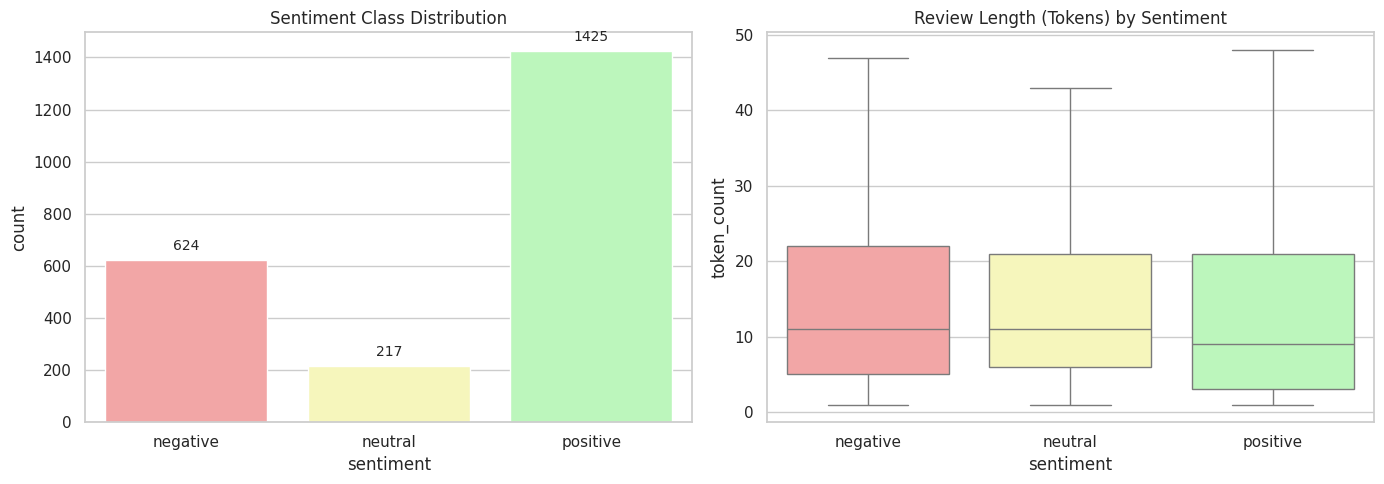

In [4]:
df['token_count'] = df['clean_content'].apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class Distribution
sns.countplot(x='sentiment', data=df, order=['negative', 'neutral', 'positive'],
              palette=['#ff9999', '#ffffb3', '#b3ffb3'], ax=axes[0])
axes[0].set_title('Sentiment Class Distribution')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 5), textcoords='offset points')

# Review Length
sns.boxplot(x='sentiment', y='token_count', data=df, order=['negative', 'neutral', 'positive'],
            palette=['#ff9999', '#ffffb3', '#b3ffb3'], ax=axes[1], showfliers=False)
axes[1].set_title('Review Length (Tokens) by Sentiment')

plt.tight_layout()
plt.show()

Splitting and TF-IDF

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_raw = df[text_col]
X_clean = df['clean_content']
y = df['sentiment']

# 80/20 Stratified Split
X_train_raw, X_test_raw, X_train_clean, X_test_clean, y_train, y_test = train_test_split(
    X_raw, X_clean, y, test_size=0.20, random_state=SEED, stratify=y
)

# TF-IDF Vectorizer
tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=5, max_df=0.8, dtype=np.float32)

X_train_tfidf = tfidf.fit_transform(X_train_clean)
X_test_tfidf = tfidf.transform(X_test_clean)

print(f" Train size: {X_train_tfidf.shape[0]} | Test size: {X_test_tfidf.shape[0]}")
print(f" Vocabulary size: {len(tfidf.vocabulary_)}")

 Train size: 1812 | Test size: 454
 Vocabulary size: 1549


Model Training and Cross Validation

In [6]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

models = {
    'MultinomialNB': MultinomialNB(alpha=1.0),
    'BalancedLogReg': LogisticRegression(class_weight='balanced', penalty='l2', C=1.0, solver='lbfgs', max_iter=1000, random_state=SEED)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = []

print("Running 5-Fold Stratified Cross-Validation...\n")
for name, model in models.items():
    cv_res = cross_validate(model, X_train_tfidf, y_train, cv=cv, scoring=['f1_macro', 'accuracy'], n_jobs=-1)

    mean_f1, std_f1 = cv_res['test_f1_macro'].mean(), cv_res['test_f1_macro'].std()
    mean_acc = cv_res['test_accuracy'].mean()

    results.append({'Model': name, 'Macro F1': f"{mean_f1:.4f} (+/- {std_f1:.4f})", 'Accuracy': f"{mean_acc:.4f}"})
    print(f" {name}: Macro F1 = {mean_f1:.4f} | Accuracy = {mean_acc:.4f}")

# Select the best model
results_df = pd.DataFrame(results)
print("\n--- CV Results ---")
print(results_df.to_string(index=False))

# Extract the actual best model object to train on full data
best_model_name = 'BalancedLogReg' if 'BalancedLogReg' in models and results[1]['Macro F1'] > results[0]['Macro F1'] else 'MultinomialNB'
best_model = models[best_model_name]
print(f"\n Selected Best Model: {best_model_name}")

Running 5-Fold Stratified Cross-Validation...

 MultinomialNB: Macro F1 = 0.4907 | Accuracy = 0.7516
 BalancedLogReg: Macro F1 = 0.5651 | Accuracy = 0.7064

--- CV Results ---
         Model            Macro F1 Accuracy
 MultinomialNB 0.4907 (+/- 0.0113)   0.7516
BalancedLogReg 0.5651 (+/- 0.0216)   0.7064

 Selected Best Model: BalancedLogReg


Evaluation and Error Diagnostics

--- Classification Report ---
              precision    recall  f1-score   support

    negative     0.6154    0.5760    0.5950       125
     neutral     0.2105    0.3721    0.2689        43
    positive     0.8314    0.7587    0.7934       286

    accuracy                         0.6718       454
   macro avg     0.5524    0.5689    0.5525       454
weighted avg     0.7131    0.6718    0.6891       454



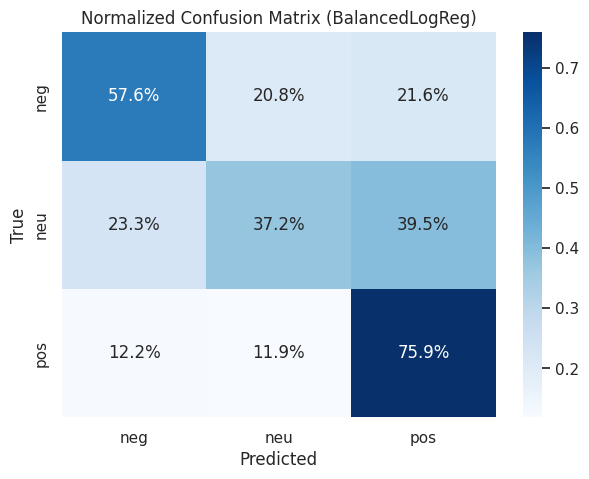

--- Top 5 False Positives (Predicted Positive, Actually Neg/Neu) ---
[NEUTRAL -> POS | Conf: 0.80] I’m visually impaired and love the app just wish I could click read aloud. Thank...
[NEGATIVE -> POS | Conf: 0.79] I don’t like there is a free trial for this app, a lot of apps that are AI do th...
[NEGATIVE -> POS | Conf: 0.74] I didn’t and could not imagine a more castrated version of chatgpt and they alwa...
[NEUTRAL -> POS | Conf: 0.71] The app works great and provides *some* of the functionality that the website gi...
[NEUTRAL -> POS | Conf: 0.68] The chat is great, but the app is very buggy....

--- Top 5 False Negatives (Actually Positive, Predicted Neg/Neu) ---
[POS -> NEGATIVE | Conf: 0.89] I keep getting an error when trying to log in with my google account. My paid ac...
[POS -> NEGATIVE | Conf: 0.85] Dear Open AI,
Please make it available in Iran. Unfortunately , Iranians cannot ...
[POS -> NEGATIVE | Conf: 0.74] So I apparently “Already had an account” so I tried clicking “F

In [7]:
from sklearn.metrics import classification_report, confusion_matrix

# Train final model and predict
best_model.fit(X_train_tfidf, y_train)
y_pred = best_model.predict(X_test_tfidf)
y_proba = best_model.predict_proba(X_test_tfidf)

print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['negative', 'neutral', 'positive'], digits=4))

# Normalized Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=['negative', 'neutral', 'positive'])
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7, 5))
sns.heatmap(cm_norm, annot=True, fmt='.1%', cmap='Blues', xticklabels=['neg', 'neu', 'pos'], yticklabels=['neg', 'neu', 'pos'])
plt.title(f'Normalized Confusion Matrix ({best_model_name})')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

# Error Diagnostics (Focal class: positive)
test_df = pd.DataFrame({'raw_text': X_test_raw.values, 'true': y_test.values, 'pred': y_pred, 'conf': y_proba.max(axis=1)})

print("--- Top 5 False Positives (Predicted Positive, Actually Neg/Neu) ---")
fps = test_df[(test_df['pred'] == 'positive') & (test_df['true'] != 'positive')].sort_values('conf', ascending=False).head(5)
for _, row in fps.iterrows():
    print(f"[{row['true'].upper()} -> POS | Conf: {row['conf']:.2f}] {row['raw_text'][:80]}...")

print("\n--- Top 5 False Negatives (Actually Positive, Predicted Neg/Neu) ---")
fns = test_df[(test_df['true'] == 'positive') & (test_df['pred'] != 'positive')].sort_values('conf', ascending=False).head(5)
for _, row in fns.iterrows():
    print(f"[POS -> {row['pred'].upper()} | Conf: {row['conf']:.2f}] {row['raw_text'][:80]}...")

E2E Pipeline & Inference with test data

In [8]:
from sklearn.pipeline import Pipeline

# Create a Scikit-Learn wrapper for our cleaning function
class ReviewCleanerTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X, y=None):
        return [clean_review(text) for text in X]

# Build the End-to-End Pipeline
serving_pipeline = Pipeline([
    ('cleaner', ReviewCleanerTransformer()),
    ('tfidf', tfidf),
    ('classifier', best_model)
])

# 3. Fit on RAW text (the pipeline handles the cleaning internally)
serving_pipeline.fit(X_train_raw, y_train)

# Save the artifact
PIPELINE_PATH = '/content/chatgpt_sentiment_pipeline.joblib'
joblib.dump(serving_pipeline, PIPELINE_PATH)
print(f" End-to-End Pipeline saved to: {PIPELINE_PATH}")

# Interactive Inference Function
def predict_review_sentiment(review_text: str) -> dict:
    """Predicts sentiment from raw text. Returns class, confidence, and probabilities."""
    if not isinstance(review_text, str) or not review_text.strip():
        return {"error": "Input must be a non-empty string."}

    prediction = serving_pipeline.predict([review_text])[0]
    probabilities = serving_pipeline.predict_proba([review_text])[0]
    classes = serving_pipeline.classes_

    pred_idx = list(classes).index(prediction)
    confidence = probabilities[pred_idx]

    return {
        "predicted_class": prediction,
        "confidence_percentage": round(confidence * 100, 2),
        "class_probabilities": {cls: round(float(prob), 3) for cls, prob in zip(classes, probabilities)}
    }

#  Test with raw, messy text
print("\n--- Testing Inference on Raw Text ---")
test_reviews = [
    "This app is amazing! It really helps me with my coding. 😍🚀",
    "Terrible experience. It keeps crashing and I can't log in. 💩💩",
    "It's okay, does the job but nothing special. 😐",
    "I love it, but the new update is not good at all."
]

for review in test_reviews:
    result = predict_review_sentiment(review)
    print(f"\nReview: '{review}'")
    print(f"Prediction: {result['predicted_class']} (Confidence: {result['confidence_percentage']}%)")

 End-to-End Pipeline saved to: /content/chatgpt_sentiment_pipeline.joblib

--- Testing Inference on Raw Text ---

Review: 'This app is amazing! It really helps me with my coding. 😍🚀'
Prediction: positive (Confidence: 73.75%)

Review: 'Terrible experience. It keeps crashing and I can't log in. 💩💩'
Prediction: negative (Confidence: 60.9%)

Review: 'It's okay, does the job but nothing special. 😐'
Prediction: positive (Confidence: 48.83%)

Review: 'I love it, but the new update is not good at all.'
Prediction: positive (Confidence: 61.79%)
